LightGBM keeps XGBoost's mathematics **unchanged**. The leaf weight is still
$w^{*} = -G/(H+\lambda)$ and the split gain is still built from
$G^2/(H+\lambda)$ terms.

What LightGBM changes is **how the search is done**, and it changes three things:

| | XGBoost (exact) | LightGBM |
|---|---|---|
| Finding thresholds | sort every feature, try every midpoint | bucket into a fixed number of **bins** |
| Growing the tree | **level-wise** &mdash; fill each depth before going deeper | **leaf-wise** &mdash; always split the most promising leaf |
| Using the rows | all of them | **GOSS** &mdash; keep large gradients, subsample small ones |

Each of these is an approximation traded for speed, and each is worked through below
with the actual numbers. At the end the tree is matched against the real `lightgbm`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from library: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


In [2]:
# ----------------------------------------------------------------------------
#  Draw a tree as a real diagram, with the split criteria written inside each
#  node. Node format:
#     {"label": "multi\nline\ntext", "kind": "split"|"leaf"|"pending",
#      "children": [(edge_text, child), ...]}
# ----------------------------------------------------------------------------

NODE_STYLE = {
    "split":   dict(fc="#dbeafe", ec="#2563eb", lw=1.8),
    "leaf0":   dict(fc="#dbeafe", ec="#1e40af", lw=1.8),
    "leaf1":   dict(fc="#fee2e2", ec="#b91c1c", lw=1.8),
    "leaf":    dict(fc="#dcfce7", ec="#15803d", lw=1.8),
    "pending": dict(fc="#f1f5f9", ec="#94a3b8", lw=1.6),
    "new":     dict(fc="#fef9c3", ec="#ca8a04", lw=2.6),
}


def _tree_layout(node, depth, counter, pos):
    kids = node.get("children") or []
    if not kids:
        x = counter[0]
        counter[0] += 1
    else:
        xs = [_tree_layout(c, depth + 1, counter, pos) for _, c in kids]
        x = float(np.mean(xs))
    pos[id(node)] = (x, -depth)
    return x


def _tree_walk(node, out):
    out.append(node)
    for _, c in (node.get("children") or []):
        _tree_walk(c, out)
    return out


def draw_tree(root, title="", ax=None, figsize=None, fontsize=8.5, edge_fontsize=8):
    pos, counter = {}, [0]
    _tree_layout(root, 0, counter, pos)
    nodes = _tree_walk(root, [])
    xs = [pos[id(n)][0] for n in nodes]
    ys = [pos[id(n)][1] for n in nodes]
    n_leaf = max(counter[0], 1)
    depth = -min(ys) + 1

    own_fig = ax is None
    if own_fig:
        figsize = figsize or (max(6.5, 2.7 * n_leaf), 0.85 + 1.45 * depth)
        fig, ax = plt.subplots(figsize=figsize)

    # edges first so boxes sit on top
    for n in nodes:
        x0, y0 = pos[id(n)]
        for edge_text, c in (n.get("children") or []):
            x1, y1 = pos[id(c)]
            ax.plot([x0, x1], [y0 - 0.22, y1 + 0.22], color="#64748b", lw=1.3, zorder=1)
            if edge_text:
                ax.text((x0 + x1) / 2, (y0 + y1) / 2 - 0.02, edge_text,
                        ha="center", va="center", fontsize=edge_fontsize,
                        color="#334155",
                        bbox=dict(boxstyle="round,pad=0.16", fc="white",
                                  ec="#cbd5e1", lw=.7), zorder=2)

    for n in nodes:
        x, y = pos[id(n)]
        style = NODE_STYLE.get(n.get("kind", "split"), NODE_STYLE["split"])
        ax.text(x, y, n["label"], ha="center", va="center", fontsize=fontsize,
                family="monospace", zorder=3,
                bbox=dict(boxstyle="round,pad=0.42", **style))

    ax.set_xlim(min(xs) - 0.7, max(xs) + 0.7)
    ax.set_ylim(min(ys) - 0.55, 0.55)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=11, fontweight="bold", pad=12)
    if own_fig:
        plt.tight_layout()
        plt.show()
    return ax


print("Tree diagram helper ready: draw_tree(root, title).")

Tree diagram helper ready: draw_tree(root, title).


---
# 1. The Task and the Starting Point

Same 12 EEG recordings and the same regression target as the XGBoost walkthrough.

One difference in setup: LightGBM starts from the **mean of $y$** rather than a fixed
constant (`boost_from_average`). That has a neat consequence worth noticing immediately.

In [3]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

In [4]:
import lightgbm as lgb
import json

ETA, LAMBDA, NUM_LEAVES = 0.3, 1.0, 3
y = y_reg.astype(float)

init_score = y.mean()
pred0 = np.full(n_samples, init_score)
g = pred0 - y
h = np.ones(n_samples)

print(f"init_score = mean(y) = {init_score:.6f}\n")
hdr = f"{'id':>6}  {'y':>7}  {'pred0':>8}  {'g = p - y':>11}  {'h':>4}"
print(hdr); print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {y[i]:>7.2f}  {pred0[i]:>8.4f}  {g[i]:>11.4f}  {h[i]:>4.0f}")
print("-" * len(hdr))
print(f"{'SUM':>6}  {y.sum():>7.2f}  {pred0.sum():>8.4f}  {g.sum():>11.6f}  {h.sum():>4.0f}")

print(f"\nG = {g.sum():.10f}   <- exactly zero, and not by accident:")
print(f"starting at the mean makes the total gradient vanish, because")
print(f"sum(mean(y) - y_i) = n*mean(y) - sum(y) = 0 by definition of the mean.")
print(f"\nSo the root similarity G^2/(H+lambda) = {g.sum()**2/(h.sum()+LAMBDA):.6f},")
print(f"and every bit of gain a split earns is pure separation of positive from")
print(f"negative gradients.")

init_score = mean(y) = 3.725000

    id        y     pred0    g = p - y     h
--------------------------------------------
 rec00     0.20    3.7250       3.5250     1
 rec01     0.50    3.7250       3.2250     1
 rec02     6.40    3.7250      -2.6750     1
 rec03     4.80    3.7250      -1.0750     1
 rec04     0.10    3.7250       3.6250     1
 rec05     9.10    3.7250      -5.3750     1
 rec06     3.50    3.7250       0.2250     1
 rec07     7.20    3.7250      -3.4750     1
 rec08     0.30    3.7250       3.4250     1
 rec09     6.90    3.7250      -3.1750     1
 rec10     1.60    3.7250       2.1250     1
 rec11     4.10    3.7250      -0.3750     1
--------------------------------------------
   SUM    44.70   44.7000    -0.000000    12

G = -0.0000000000   <- exactly zero, and not by accident:
starting at the mean makes the total gradient vanish, because
sum(mean(y) - y_i) = n*mean(y) - sum(y) = 0 by definition of the mean.

So the root similarity G^2/(H+lambda) = 0.000000,
and 

---
# 2. Histogram Binning

Exact split finding sorts a feature and tests every midpoint: $O(n \log n)$ per feature
per node, and $n-1$ candidate thresholds.

LightGBM instead pushes every value into one of `max_bin` buckets **once, before
training**, and then only ever considers **bin boundaries** as thresholds. With 255 bins
the number of candidates stops growing with $n$ entirely.

To make the bucketing visible, `max_bin` is set to 4 below &mdash; so 12 distinct values
collapse into 4 groups and only 3 thresholds survive.

In [5]:
MAX_BIN_DEMO = 4

def make_bins(col, max_bin):
    """Equal-frequency bin edges, the same idea LightGBM uses."""
    qs = np.linspace(0, 100, max_bin + 1)[1:-1]
    edges = np.unique(np.percentile(col, qs))
    return edges

def to_bin(col, edges):
    return np.searchsorted(edges, col, side="left")

f_demo = 1        # spike_rate
edges = make_bins(X[:, f_demo], MAX_BIN_DEMO)
bins  = to_bin(X[:, f_demo], edges)

print(f"feature '{feature_names[f_demo]}' with max_bin = {MAX_BIN_DEMO}\n")
print(f"bin edges: {np.round(edges, 3)}\n")
order = np.argsort(X[:, f_demo])
print(f"{'id':>6}  {'value':>8}  {'bin':>4}  {'g':>9}  {'h':>4}")
print("-" * 38)
for i in order:
    print(f"{rec_ids[i]:>6}  {X[i, f_demo]:>8.2f}  {bins[i]:>4}  {g[i]:>9.4f}  {h[i]:>4.0f}")
print("-" * 38)

print(f"\nexact search would test {len(np.unique(X[:, f_demo]))-1} thresholds;")
print(f"histogram search tests {MAX_BIN_DEMO-1}.")

feature 'spike_rate' with max_bin = 4

bin edges: [1.1   3.55  6.275]

    id     value   bin          g     h
--------------------------------------
 rec04      0.30     0     3.6250     1
 rec00      0.50     0     3.5250     1
 rec08      0.80     0     3.4250     1
 rec01      1.20     1     3.2250     1
 rec06      1.90     1     0.2250     1
 rec10      2.40     1     2.1250     1
 rec11      4.70     2    -0.3750     1
 rec03      5.10     2    -1.0750     1
 rec09      6.10     2    -3.1750     1
 rec02      6.80     3    -2.6750     1
 rec07      7.40     3    -3.4750     1
 rec05      8.20     3    -5.3750     1
--------------------------------------

exact search would test 11 thresholds;
histogram search tests 3.


### Building the histogram

For each bin LightGBM accumulates just two numbers &mdash; the sum of gradients and the sum
of Hessians:

$$\text{Hist}[b] = \Big(\textstyle\sum_{i:\,\text{bin}(i)=b} g_i,\;\; \sum_{i:\,\text{bin}(i)=b} h_i\Big)$$

This is a single $O(n)$ pass. Everything after it costs $O(\text{bins})$ and never
touches the rows again.

In [6]:
def histogram(idx, feat_bins, n_bins, gg, hh):
    Gh = np.zeros(n_bins); Hh = np.zeros(n_bins); Ch = np.zeros(n_bins)
    np.add.at(Gh, feat_bins[idx], gg[idx])
    np.add.at(Hh, feat_bins[idx], hh[idx])
    np.add.at(Ch, feat_bins[idx], 1)
    return Gh, Hh, Ch

root = np.arange(n_samples)
Gh, Hh, Ch = histogram(root, bins, MAX_BIN_DEMO, g, h)

print(f"histogram for '{feature_names[f_demo]}'\n")
print(f"{'bin':>4}  {'count':>6}  {'sum g':>10}  {'sum h':>7}")
print("-" * 32)
for b in range(MAX_BIN_DEMO):
    print(f"{b:>4}  {int(Ch[b]):>6}  {Gh[b]:>10.4f}  {Hh[b]:>7.1f}")
print("-" * 32)
print(f"{'ALL':>4}  {int(Ch.sum()):>6}  {Gh.sum():>10.4f}  {Hh.sum():>7.1f}")
print(f"\ntotals match the full dataset: G {np.isclose(Gh.sum(), g.sum())}, "
      f"H {np.isclose(Hh.sum(), h.sum())}")

histogram for 'spike_rate'

 bin   count       sum g    sum h
--------------------------------
   0       3     10.5750      3.0
   1       3      5.5750      3.0
   2       3     -4.6250      3.0
   3       3    -11.5250      3.0
--------------------------------
 ALL      12     -0.0000     12.0

totals match the full dataset: G True, H True


### Scanning the histogram

Finding the best threshold is now a single left-to-right sweep accumulating prefix sums.
The right side never has to be computed &mdash; it is the total minus the left:

$$G_R = G_{\text{total}} - G_L, \qquad H_R = H_{\text{total}} - H_L$$

In [7]:
def similarity(G_, H_, lam=LAMBDA):
    return G_ * G_ / (H_ + lam)

def scan(Gh, Hh, Ch, lam=LAMBDA, verbose=False):
    Gt, Ht = Gh.sum(), Hh.sum()
    Sp = similarity(Gt, Ht, lam)
    best = (-np.inf, None)
    GL = HL = CL = 0.0
    if verbose:
        print(f"{'split after bin':>16}  {'G_L':>9}  {'H_L':>6}  {'G_R':>9}  {'H_R':>6}  "
              f"{'S_L':>9}  {'S_R':>9}  {'gain':>9}")
        print("-" * 88)
    for b in range(len(Gh) - 1):
        GL += Gh[b]; HL += Hh[b]; CL += Ch[b]
        GR, HR = Gt - GL, Ht - HL
        if CL == 0 or CL == Ch.sum():
            continue
        gain = 0.5 * (similarity(GL, HL, lam) + similarity(GR, HR, lam) - Sp)
        if verbose:
            print(f"{b:>16}  {GL:>9.4f}  {HL:>6.1f}  {GR:>9.4f}  {HR:>6.1f}  "
                  f"{similarity(GL,HL,lam):>9.4f}  {similarity(GR,HR,lam):>9.4f}  {gain:>9.4f}")
        if gain > best[0]:
            best = (gain, b)
    return best

print(f"prefix-sum scan over the {MAX_BIN_DEMO} bins of '{feature_names[f_demo]}'\n")
best_gain, best_bin = scan(Gh, Hh, Ch, verbose=True)
print("-" * 88)
print(f"\nbest: split after bin {best_bin}, gain {best_gain:.6f} "
      f"(lightgbm would print {2*best_gain:.6f})")
print(f"which corresponds to the threshold {edges[best_bin]:.4f}")

exact_best = (-np.inf, None)
v = np.unique(X[:, f_demo])
for t in (v[:-1] + v[1:]) / 2:
    m = X[:, f_demo] <= t
    gg = 0.5 * (similarity(g[m].sum(), h[m].sum())
                + similarity(g[~m].sum(), h[~m].sum())
                - similarity(g.sum(), h.sum()))
    if gg > exact_best[0]:
        exact_best = (gg, float(t))
print(f"\nexact search over all {len(v)-1} thresholds: gain {exact_best[0]:.6f} "
      f"at {exact_best[1]:.3f}")
print(f"histogram search with only {MAX_BIN_DEMO} bins : gain {best_gain:.6f} "
      f"at {edges[best_bin]:.3f}")
print(f"\nsame gain? {np.isclose(best_gain, exact_best[0])}")
print("With 4 bins the approximation happens to land on the same split. Coarser")
print("bins lose accuracy; finer bins cost more. max_bin is exactly that dial.")

prefix-sum scan over the 4 bins of 'spike_rate'

 split after bin        G_L     H_L        G_R     H_R        S_L        S_R       gain
----------------------------------------------------------------------------------------
               0    10.5750     3.0   -10.5750     9.0    27.9577    11.1831    19.5704
               1    16.1500     6.0   -16.1500     6.0    37.2604    37.2604    37.2604
               2    11.5250     9.0   -11.5250     3.0    13.2826    33.2064    23.2445
----------------------------------------------------------------------------------------

best: split after bin 1, gain 37.260357 (lightgbm would print 74.520714)
which corresponds to the threshold 3.5500

exact search over all 11 thresholds: gain 37.260357 at 3.550
histogram search with only 4 bins : gain 37.260357 at 3.550

same gain? True
With 4 bins the approximation happens to land on the same split. Coarser
bins lose accuracy; finer bins cost more. max_bin is exactly that dial.


### Why this is fast

Exact split finding costs $O(n \log n)$ per feature per node. Histogram building costs
$O(n)$ **once**, and every node after that costs $O(\#\text{bins})$ regardless of how
many rows it holds.

On 12 rows this is irrelevant. The table below scales the row count up to make the
difference visible.

In [8]:
import time
rng = np.random.default_rng(0)

print(f"{'rows':>9}  {'exact (ms)':>11}  {'histogram (ms)':>15}  {'speedup':>8}")
print("-" * 50)
for N in (1000, 10000, 100000, 500000):
    col = rng.normal(size=N)
    gr  = rng.normal(size=N)
    hr  = np.ones(N)

    t0 = time.perf_counter()
    o = np.argsort(col)
    cg = np.cumsum(gr[o]); ch = np.cumsum(hr[o])
    Gt, Ht = cg[-1], ch[-1]
    _ = np.max(similarity(cg[:-1], ch[:-1]) + similarity(Gt - cg[:-1], Ht - ch[:-1]))
    t_exact = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    bn = np.clip(((col - col.min()) / (np.ptp(col) + 1e-12) * 255).astype(np.int32), 0, 254)
    Gb = np.zeros(255); Hb = np.zeros(255)
    np.add.at(Gb, bn, gr); np.add.at(Hb, bn, hr)
    cg2 = np.cumsum(Gb); ch2 = np.cumsum(Hb)
    _ = np.max(similarity(cg2[:-1], ch2[:-1]) + similarity(cg2[-1]-cg2[:-1], ch2[-1]-ch2[:-1]))
    t_hist = (time.perf_counter() - t0) * 1000

    print(f"{N:>9}  {t_exact:>11.2f}  {t_hist:>15.2f}  {t_exact/max(t_hist,1e-9):>7.1f}x")
print("-" * 50)
print("\nAnd the real saving is bigger than this: the binning pass happens ONCE for")
print("the whole training run, while the sort in exact mode happens at every node.")

     rows   exact (ms)   histogram (ms)   speedup
--------------------------------------------------
     1000         0.11             0.08      1.4x
    10000         0.42             0.10      4.3x
   100000         4.52             0.69      6.5x
   500000        32.82             6.11      5.4x
--------------------------------------------------

And the real saving is bigger than this: the binning pass happens ONCE for
the whole training run, while the sort in exact mode happens at every node.


### The histogram subtraction trick

A second saving, and it is nearly free. After splitting a node, LightGBM builds the
histogram for the **smaller** child only, then obtains the other by subtraction:

$$\text{Hist}_{\text{sibling}} = \text{Hist}_{\text{parent}} - \text{Hist}_{\text{child}}$$

So the cost of a node pair is set by the smaller child, not the parent.

In [9]:
m_demo = X[:, f_demo] <= edges[best_bin]
left_idx, right_idx = root[m_demo], root[~m_demo]
small, large = (left_idx, right_idx) if len(left_idx) <= len(right_idx) else (right_idx, left_idx)

Gp, Hp, Cp = histogram(root,  bins, MAX_BIN_DEMO, g, h)
Gs, Hs, Cs = histogram(small, bins, MAX_BIN_DEMO, g, h)
Gsub, Hsub, Csub = Gp - Gs, Hp - Hs, Cp - Cs
Gd, Hd, Cd = histogram(large, bins, MAX_BIN_DEMO, g, h)

print(f"parent has {len(root)} rows; children have {len(small)} and {len(large)}\n")
print(f"{'bin':>4}  {'parent G':>10}  {'small G':>9}  {'parent-small':>13}  "
      f"{'direct G':>9}  {'equal':>6}")
print("-" * 60)
for b in range(MAX_BIN_DEMO):
    print(f"{b:>4}  {Gp[b]:>10.4f}  {Gs[b]:>9.4f}  {Gsub[b]:>13.4f}  {Gd[b]:>9.4f}  "
          f"{str(np.isclose(Gsub[b], Gd[b])):>6}")
print("-" * 60)
print(f"\nsubtraction reproduces the sibling histogram exactly: "
      f"G {np.allclose(Gsub, Gd)}, H {np.allclose(Hsub, Hd)}, count {np.allclose(Csub, Cd)}")
print(f"\nrows actually scanned: {len(small)} instead of {len(large)} "
      f"({len(large)-len(small)} saved at this node alone)")

parent has 12 rows; children have 6 and 6

 bin    parent G    small G   parent-small   direct G   equal
------------------------------------------------------------
   0     10.5750    10.5750         0.0000     0.0000    True
   1      5.5750     5.5750         0.0000     0.0000    True
   2     -4.6250     0.0000        -4.6250    -4.6250    True
   3    -11.5250     0.0000       -11.5250   -11.5250    True
------------------------------------------------------------

subtraction reproduces the sibling histogram exactly: G True, H True, count True

rows actually scanned: 6 instead of 6 (0 saved at this node alone)


---
# 3. Leaf-wise Growth

This is the change with the biggest effect on the shape of the tree.

* **Level-wise** (XGBoost's default): split every node at depth $d$ before touching
  depth $d+1$. The tree stays balanced. Capacity is controlled by `max_depth`.
* **Leaf-wise** (LightGBM): keep every splittable leaf in a queue, and always split the
  one with the **highest gain**, wherever it is. The tree becomes deep and lopsided.
  Capacity is controlled by **`num_leaves`**.

For a fixed number of leaves, leaf-wise reaches a lower loss &mdash; it spends its budget
where the gain is, instead of spreading it evenly. The cost is that it can drive a
single branch very deep and overfit, which is why `num_leaves` (and
`min_data_in_leaf`) matter far more than `max_depth` in LightGBM.

In [10]:
def best_split_exact(idx, gg, hh):
    best = (-np.inf, None, None)
    for f in range(n_features):
        v = np.unique(X[idx, f])
        if len(v) < 2:
            continue
        for t in (v[:-1] + v[1:]) / 2:
            m = X[idx, f] <= t
            gain = 0.5 * (similarity(gg[idx][m].sum(), hh[idx][m].sum())
                          + similarity(gg[idx][~m].sum(), hh[idx][~m].sum())
                          - similarity(gg[idx].sum(), hh[idx].sum()))
            if gain > best[0]:
                best = (gain, f, float(t))
    return best


def grow_leafwise(num_leaves, gg, hh, verbose=True):
    leaves = [{"idx": np.arange(n_samples), "id": 0, "depth": 0}]
    nxt = 1
    order = []
    while len(leaves) < num_leaves:
        cands = []
        for li, lf in enumerate(leaves):
            if len(lf["idx"]) < 2:
                continue
            gain, f, t = best_split_exact(lf["idx"], gg, hh)
            if f is not None and gain > 0:
                cands.append((gain, li, f, t))
        if not cands:
            break
        gain, li, f, t = max(cands, key=lambda z: z[0])
        lf = leaves.pop(li)
        m = X[lf["idx"], f] <= t
        if verbose:
            others = sorted((c[0] for c in cands), reverse=True)[1:]
            print(f"  step {len(order)+1}: split leaf holding {len(lf['idx'])} rows on "
                  f"{feature_names[f]} <= {t:.2f}   gain {gain:.4f}"
                  + (f"   (next best leaf offered {others[0]:.4f})" if others else ""))
        leaves.append({"idx": lf["idx"][m],  "id": nxt,     "depth": lf["depth"]+1})
        leaves.append({"idx": lf["idx"][~m], "id": nxt + 1, "depth": lf["depth"]+1})
        nxt += 2
        order.append((gain, f, t))
    return leaves, order


def grow_levelwise(max_depth, gg, hh):
    leaves = [{"idx": np.arange(n_samples), "depth": 0}]
    for d in range(max_depth):
        new = []
        for lf in leaves:
            if len(lf["idx"]) < 2:
                new.append(lf); continue
            gain, f, t = best_split_exact(lf["idx"], gg, hh)
            if f is None or gain <= 0:
                new.append(lf); continue
            m = X[lf["idx"], f] <= t
            new.append({"idx": lf["idx"][m],  "depth": d + 1})
            new.append({"idx": lf["idx"][~m], "depth": d + 1})
        leaves = new
    return leaves


def total_obj(leaves, gg, hh):
    """Sum of -0.5 * G^2/(H+lambda): lower is better."""
    return -0.5 * sum(similarity(gg[lf["idx"]].sum(), hh[lf["idx"]].sum()) for lf in leaves)


print("LEAF-WISE growth (LightGBM), num_leaves = 4:\n")
lw, order = grow_leafwise(4, g, h)
print(f"\nresulting leaves: {[len(l['idx']) for l in lw]}  depths {[l['depth'] for l in lw]}")
print(f"objective: {total_obj(lw, g, h):.6f}")

print("\n\nLEVEL-WISE growth (XGBoost style), max_depth = 2 -> also 4 leaves:\n")
lv = grow_levelwise(2, g, h)
print(f"resulting leaves: {[len(l['idx']) for l in lv]}  depths {[l['depth'] for l in lv]}")
print(f"objective: {total_obj(lv, g, h):.6f}")

print(f"\n{'strategy':>12}  {'leaves':>7}  {'max depth':>10}  {'objective':>11}")
print("-" * 46)
print(f"{'leaf-wise':>12}  {len(lw):>7}  {max(l['depth'] for l in lw):>10}  {total_obj(lw,g,h):>11.4f}")
print(f"{'level-wise':>12}  {len(lv):>7}  {max(l['depth'] for l in lv):>10}  {total_obj(lv,g,h):>11.4f}")
print("-" * 46)
print(f"\nOn THIS dataset the two strategies produce the identical tree - same")
print(f"objective, same depth. 12 rows with clean structure simply do not offer")
print(f"the highest-gain leaf anywhere for level-wise order to matter.")
print(f"\nThat is worth stating plainly rather than asserting a difference that")
print(f"is not there. A dataset where it DOES matter is built below.")

LEAF-WISE growth (LightGBM), num_leaves = 4:

  step 1: split leaf holding 12 rows on spike_rate <= 3.55   gain 37.2604
  step 2: split leaf holding 6 rows on line_length <= 40.00   gain 3.3292   (next best leaf offered 1.3342)
  step 3: split leaf holding 6 rows on line_length <= 27.50   gain 1.3342

resulting leaves: [2, 4, 4, 2]  depths [2, 2, 2, 2]
objective: -41.923833


LEVEL-WISE growth (XGBoost style), max_depth = 2 -> also 4 leaves:

resulting leaves: [4, 2, 2, 4]  depths [2, 2, 2, 2]
objective: -41.923833

    strategy   leaves   max depth    objective
----------------------------------------------
   leaf-wise        4           2     -41.9238
  level-wise        4           2     -41.9238
----------------------------------------------

On THIS dataset the two strategies produce the identical tree - same
objective, same depth. 12 rows with clean structure simply do not offer
the highest-gain leaf anywhere for level-wise order to matter.

That is worth stating plainly rather 

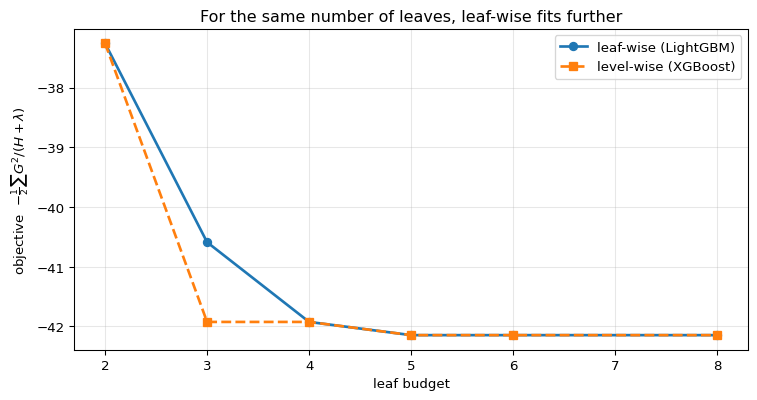

 leaves    leaf-wise   level-wise
---------------------------------
      2     -37.2604     -37.2604
      3     -40.5896     -41.9238
      4     -41.9238     -41.9238
      5     -42.1450     -42.1450
      6     -42.1450     -42.1450
      8     -42.1450     -42.1450
---------------------------------

(lower is better; on this data the two curves lie exactly on top of
each other - the leaf budget, not the growth order, is what binds here.)


In [11]:
counts = [2, 3, 4, 5, 6, 8]
lw_obj, lv_obj = [], []
for k in counts:
    lw_obj.append(total_obj(grow_leafwise(k, g, h, verbose=False)[0], g, h))
    d = int(np.ceil(np.log2(k)))
    lv_obj.append(total_obj(grow_levelwise(d, g, h), g, h))

plt.figure(figsize=(8, 4.3))
plt.plot(counts, lw_obj, "o-", lw=2, label="leaf-wise (LightGBM)")
plt.plot(counts, lv_obj, "s--", lw=2, label="level-wise (XGBoost)")
plt.xlabel("leaf budget"); plt.ylabel("objective  $-\\frac{1}{2}\\sum G^2/(H+\\lambda)$")
plt.title("For the same number of leaves, leaf-wise fits further")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print(f"{'leaves':>7}  {'leaf-wise':>11}  {'level-wise':>11}")
print("-" * 33)
for k, a, b in zip(counts, lw_obj, lv_obj):
    print(f"{k:>7}  {a:>11.4f}  {b:>11.4f}")
print("-" * 33)
print(f"\n(lower is better; on this data the two curves lie exactly on top of")
print(f"each other - the leaf budget, not the growth order, is what binds here.)")

### The two growth strategies, drawn

The diagrams below are built with the **same leaf budget of 4** and the same gain
formula. Only the choice of *which leaf to split next* differs.

Level-wise fills each depth completely before descending. Leaf-wise repeatedly picks the
highest-gain leaf anywhere in the tree.

On this 12-row table they happen to produce **the same tree** - the dataset is too small
and too cleanly separated for the orders to diverge. The section after this builds a
dataset where they genuinely differ.

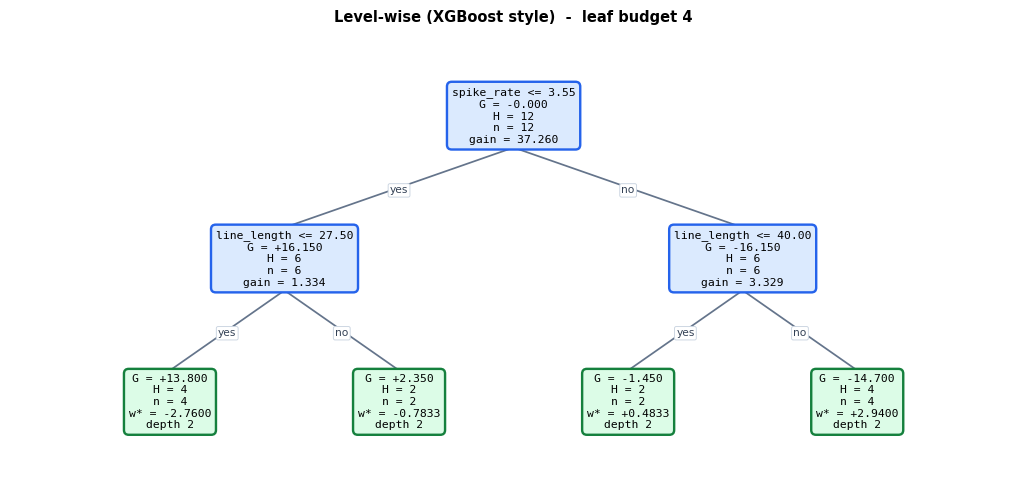

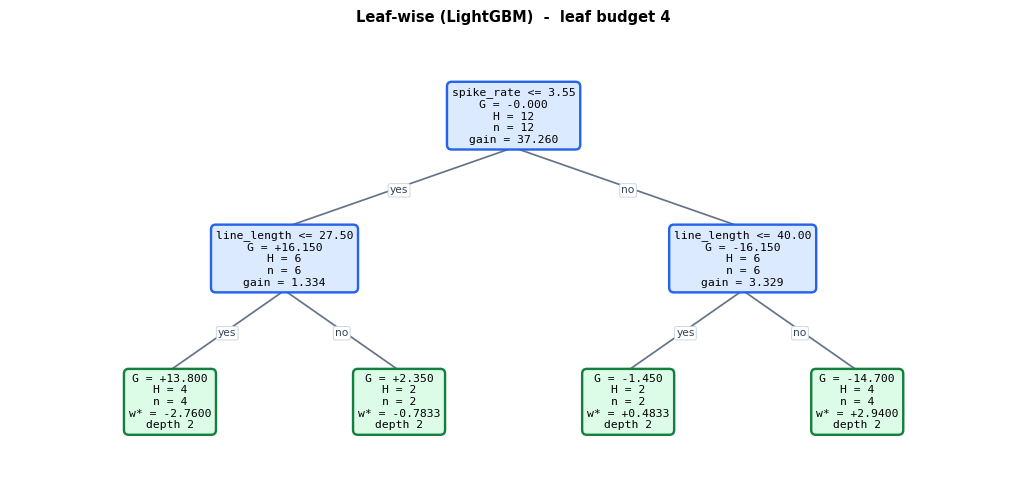

Both trees spent exactly 3 splits, and here they spent them the same way.
On 12 well-separated rows the highest-gain leaf happens to be the next
one in level order anyway, so the two strategies coincide.


In [12]:
def lgb_label(idx, question=None, gain=None, depth=None):
    G_, H_ = g[idx].sum(), h[idx].sum()
    lines = []
    if question:
        lines.append(question)
    lines.append(f"G = {G_:+.3f}")
    lines.append(f"H = {H_:.0f}")
    lines.append(f"n = {len(idx)}")
    if gain is not None:
        lines.append(f"gain = {gain:.3f}")
    else:
        lines.append(f"w* = {-G_/(H_+LAMBDA):+.4f}")
        if depth is not None:
            lines.append(f"depth {depth}")
    return chr(10).join(lines)


def build_diagram(idx, budget, strategy, depth=0):
    """Grow to a leaf budget under either strategy, returning a diagram dict."""
    leaves = [{"idx": idx, "depth": 0, "node": None}]
    root = {"idx": idx, "depth": 0, "children": None, "gain": None, "q": None}
    nodes = [root]

    def split_node(nd):
        gain, f, t = best_split_exact(nd["idx"], g, h)
        if f is None or gain <= 0:
            return None
        m = X[nd["idx"], f] <= t
        nd["q"] = f"{feature_names[f]} <= {t:.2f}"
        nd["gain"] = gain
        nd["children"] = [
            {"idx": nd["idx"][m],  "depth": nd["depth"]+1, "children": None, "gain": None, "q": None},
            {"idx": nd["idx"][~m], "depth": nd["depth"]+1, "children": None, "gain": None, "q": None},
        ]
        return nd["children"]

    open_leaves = [root]
    while len(open_leaves) < budget:
        cands = []
        for nd in open_leaves:
            if len(nd["idx"]) < 2:
                continue
            gain, f, t = best_split_exact(nd["idx"], g, h)
            if f is not None and gain > 0:
                cands.append((gain, nd))
        if not cands:
            break
        if strategy == "leafwise":
            gain, nd = max(cands, key=lambda z: z[0])
        else:
            shallowest = min(c[1]["depth"] for c in cands)
            gain, nd = max([c for c in cands if c[1]["depth"] == shallowest],
                           key=lambda z: z[0])
        kids = split_node(nd)
        open_leaves = [x for x in open_leaves if x is not nd]   # identity, not ==
        open_leaves.extend(kids)

    def to_dict(nd):
        if nd["children"] is None:
            return {"kind": "leaf", "label": lgb_label(nd["idx"], depth=nd["depth"]),
                    "children": []}
        return {"kind": "split",
                "label": lgb_label(nd["idx"], nd["q"], nd["gain"]),
                "children": [("yes", to_dict(nd["children"][0])),
                             ("no",  to_dict(nd["children"][1]))]}

    return to_dict(root)


for strat, name in (("levelwise", "Level-wise (XGBoost style)"),
                    ("leafwise",  "Leaf-wise (LightGBM)")):
    d = build_diagram(np.arange(n_samples), 4, strat)
    draw_tree(d, title=f"{name}  -  leaf budget 4")

print(f"Both trees spent exactly 3 splits, and here they spent them the same way.")
print(f"On 12 well-separated rows the highest-gain leaf happens to be the next")
print(f"one in level order anyway, so the two strategies coincide.")

### A dataset where the growth order really does matter

The two strategies diverge when the **signal is concentrated**: one region of the feature
needs many splits to describe, the rest needs almost none.

Below, `y` oscillates sharply for $x < 0.3$ and is flat afterwards. Level-wise spends
half its budget describing the flat region, because it is obliged to fill each depth.
Leaf-wise pours the budget into the oscillating part, where the gain is.

400 rows; y oscillates for x < 0.3 and is flat above it

 budget   leaf-wise obj   level-wise obj   lw depth   lv depth   leaf-wise better?
----------------------------------------------------------------------------------
      4         -199.47          -153.72          3          2                True
      6         -212.42          -212.42          3          3                True
      8         -218.35          -215.45          4          3                True
     12         -220.62          -220.00          5          4                True
     16         -220.62          -220.62          5          5                True
----------------------------------------------------------------------------------

leaf-wise is never worse: True
and at budget 4 it is far better (-199.5 vs -153.7)


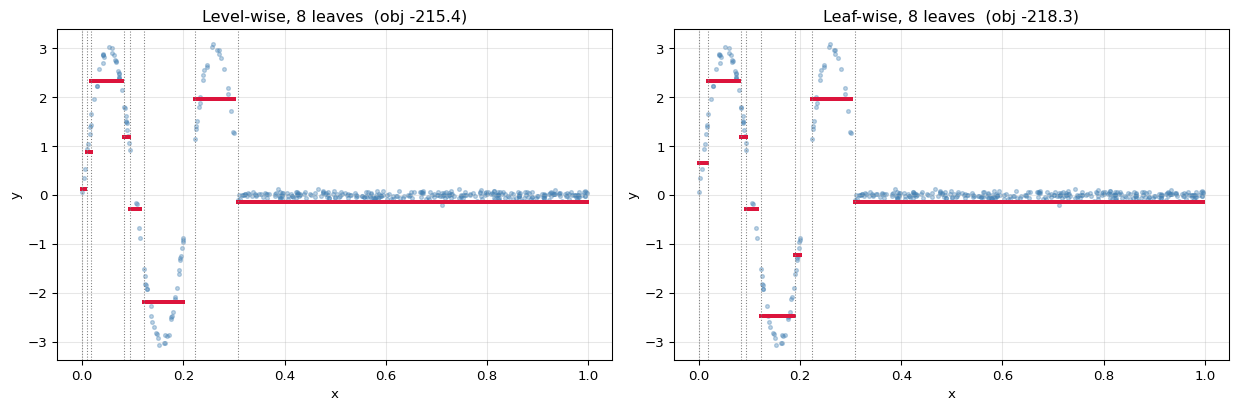

Red segments are the leaves. Level-wise wastes cuts on the flat right side;
leaf-wise concentrates them on the left where the function actually moves.

This is why num_leaves - not max_depth - is the capacity knob in LightGBM:
a depth limit barely constrains a tree that grows in one direction, and a
large num_leaves on a small dataset overfits quickly.


In [13]:
rng_c = np.random.default_rng(0)
Nc = 400
xc = rng_c.uniform(0, 1, Nc)
yc = np.where(xc < 0.3, np.sin(30 * xc) * 3.0, 0.0) + rng_c.normal(0, .05, Nc)
Xc = xc[:, None]

gc = np.full(Nc, yc.mean()) - yc
hc = np.ones(Nc)

def sim_c(G_, H_):
    return G_ * G_ / (H_ + LAMBDA)

def best_c(idx):
    b = (-np.inf, None)
    v = np.unique(Xc[idx, 0])
    if len(v) < 2:
        return b
    for t in (v[:-1] + v[1:]) / 2:
        m = Xc[idx, 0] <= t
        if m.sum() < 2 or (~m).sum() < 2:
            continue
        gain = 0.5 * (sim_c(gc[idx][m].sum(), hc[idx][m].sum())
                      + sim_c(gc[idx][~m].sum(), hc[idx][~m].sum())
                      - sim_c(gc[idx].sum(), hc[idx].sum()))
        if gain > b[0]:
            b = (gain, float(t))
    return b

def grow_c(budget, strategy):
    root = {"idx": np.arange(Nc), "d": 0}
    open_leaves = [root]
    while len(open_leaves) < budget:
        cands = []
        for nd in open_leaves:
            gain, t = best_c(nd["idx"])
            if t is not None and gain > 0:
                cands.append((gain, nd, t))
        if not cands:
            break
        if strategy == "leafwise":
            gain, nd, t = max(cands, key=lambda z: z[0])
        else:
            shallow = min(c[1]["d"] for c in cands)
            gain, nd, t = max([c for c in cands if c[1]["d"] == shallow],
                              key=lambda z: z[0])
        m = Xc[nd["idx"], 0] <= t
        kids = [{"idx": nd["idx"][m], "d": nd["d"] + 1},
                {"idx": nd["idx"][~m], "d": nd["d"] + 1}]
        open_leaves = [q for q in open_leaves if q is not nd] + kids
    return open_leaves

def obj_c(leaves):
    return -0.5 * sum(sim_c(gc[q["idx"]].sum(), hc[q["idx"]].sum()) for q in leaves)

print(f"{Nc} rows; y oscillates for x < 0.3 and is flat above it")
print()
print(f"{'budget':>7}  {'leaf-wise obj':>14}  {'level-wise obj':>15}  "
      f"{'lw depth':>9}  {'lv depth':>9}  {'leaf-wise better?':>18}")
print("-" * 82)
budgets = [4, 6, 8, 12, 16]
lw_o, lv_o = [], []
for B in budgets:
    lw, lv = grow_c(B, "leafwise"), grow_c(B, "levelwise")
    a, b_ = obj_c(lw), obj_c(lv)
    lw_o.append(a); lv_o.append(b_)
    print(f"{B:>7}  {a:>14.2f}  {b_:>15.2f}  {max(q['d'] for q in lw):>9}  "
          f"{max(q['d'] for q in lv):>9}  {str(a <= b_ + 1e-9):>18}")
print("-" * 82)
print()
print(f"leaf-wise is never worse: {all(a <= b_ + 1e-9 for a, b_ in zip(lw_o, lv_o))}")
print(f"and at budget 4 it is far better ({lw_o[0]:.1f} vs {lv_o[0]:.1f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, strat, name in zip(axes, ("levelwise", "leafwise"),
                           ("Level-wise", "Leaf-wise")):
    leaves = grow_c(8, strat)
    o = np.argsort(xc)
    ax.scatter(xc, yc, s=8, alpha=.35, color="steelblue")
    for q in leaves:
        xs = Xc[q["idx"], 0]
        pred = -gc[q["idx"]].sum() / (hc[q["idx"]].sum() + LAMBDA)
        ax.plot([xs.min(), xs.max()], [pred, pred], lw=3, color="crimson")
        ax.axvline(xs.min(), color="grey", ls=":", lw=.8)
    ax.set(xlabel="x", ylabel="y", title=f"{name}, 8 leaves  (obj {obj_c(leaves):.1f})")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Red segments are the leaves. Level-wise wastes cuts on the flat right side;")
print("leaf-wise concentrates them on the left where the function actually moves.")
print()
print("This is why num_leaves - not max_depth - is the capacity knob in LightGBM:")
print("a depth limit barely constrains a tree that grows in one direction, and a")
print("large num_leaves on a small dataset overfits quickly.")

---
# 4. GOSS &mdash; Gradient-based One-Side Sampling

A row with a gradient near zero is already well predicted and contributes almost nothing
to any split's gain. GOSS exploits that:

1. Sort rows by $|g_i|$ and keep the top $a$ fraction &mdash; the **under-fitted** rows.
2. Randomly sample a $b$ fraction of the remaining rows.
3. **Amplify** the sampled ones by $\dfrac{1-a}{b}$ when accumulating $G$ and $H$.

The amplification is the important part. Without it, throwing away most small-gradient
rows would bias the gain estimate; with it, the histogram remains an approximately
unbiased estimate of the full-data one.

In [14]:
a_frac, b_frac = 0.3, 0.3
top_k = int(a_frac * n_samples)
rest_k = int(b_frac * n_samples)
amp = (1 - a_frac) / b_frac

srt = np.argsort(-np.abs(g))
big, rest = srt[:top_k], srt[top_k:]
rng_goss = np.random.default_rng(3)
small = rng_goss.choice(rest, size=rest_k, replace=False)

print(f"a = {a_frac} -> keep the {top_k} largest |g|")
print(f"b = {b_frac} -> sample {rest_k} of the remaining {len(rest)}")
print(f"amplification factor (1-a)/b = ({1-a_frac})/{b_frac} = {amp:.4f}\n")

print(f"{'id':>6}  {'g':>9}  {'|g|':>8}  {'group':>10}  {'weight':>8}  {'g used':>9}")
print("-" * 58)
w_goss = np.zeros(n_samples)
for i in srt:
    if i in set(big.tolist()):
        grp, wt = "LARGE", 1.0
    elif i in set(small.tolist()):
        grp, wt = "sampled", amp
    else:
        grp, wt = "dropped", 0.0
    w_goss[i] = wt
    print(f"{rec_ids[i]:>6}  {g[i]:>9.4f}  {abs(g[i]):>8.4f}  {grp:>10}  {wt:>8.4f}  "
          f"{wt*g[i]:>9.4f}")
print("-" * 58)

used = w_goss > 0
print(f"\nrows used: {int(used.sum())} of {n_samples} "
      f"({used.mean():.0%}) - the rest are skipped entirely\n")

full_gain, ff, ft = best_split_exact(np.arange(n_samples), g, h)
gg_goss, hh_goss = g * w_goss, h * w_goss
goss_gain, gf, gt = best_split_exact(np.arange(n_samples), gg_goss, hh_goss)

print(f"best split on FULL data : {feature_names[ff]} <= {ft:.2f}   gain {full_gain:.4f}")
print(f"best split under GOSS   : {feature_names[gf]} <= {gt:.2f}   gain {goss_gain:.4f}")
print(f"same split chosen? {ff == gf and np.isclose(ft, gt)}")
print(f"\n>>> On 12 rows GOSS throws away half the data and lands on a DIFFERENT")
print(f">>> split, with a gain even larger than the full-data optimum. That is not")
print(f">>> a bug in the method - it is a sample far too small for it to mean")
print(f">>> anything. GOSS is a large-n technique, so it is tested properly below.")

a = 0.3 -> keep the 3 largest |g|
b = 0.3 -> sample 3 of the remaining 9
amplification factor (1-a)/b = (0.7)/0.3 = 2.3333

    id          g       |g|       group    weight     g used
----------------------------------------------------------
 rec05    -5.3750    5.3750       LARGE    1.0000    -5.3750
 rec04     3.6250    3.6250       LARGE    1.0000     3.6250
 rec00     3.5250    3.5250       LARGE    1.0000     3.5250
 rec07    -3.4750    3.4750     sampled    2.3333    -8.1083
 rec08     3.4250    3.4250     sampled    2.3333     7.9917
 rec01     3.2250    3.2250     dropped    0.0000     0.0000
 rec09    -3.1750    3.1750     dropped    0.0000    -0.0000
 rec02    -2.6750    2.6750     dropped    0.0000    -0.0000
 rec10     2.1250    2.1250     sampled    2.3333     4.9583
 rec03    -1.0750    1.0750     dropped    0.0000    -0.0000
 rec11    -0.3750    0.3750     dropped    0.0000    -0.0000
 rec06     0.2250    0.2250     dropped    0.0000     0.0000
------------------------

### Does the amplification actually work?

The claim is that $\frac{1-a}{b}$ makes the subsampled gain an approximately
**unbiased** estimate of the full-data gain. On 12 rows that cannot be seen. The
experiment below uses 5000 rows and repeats the sampling 200 times, comparing:

* **GOSS with amplification** &mdash; as LightGBM does it,
* **the same subset without amplification** &mdash; i.e. naively dropping rows,

against the true full-data gain.

N = 5000 rows, a = 0.3, b = 0.3, 200 repetitions

                   estimator    mean gain       std   bias vs truth
--------------------------------------------------------------------
           full data (truth)      582.191     0.000           0.000
           GOSS with (1-a)/b      547.837     6.114         -34.354
 same rows, no amplification      506.542     3.505         -75.649
--------------------------------------------------------------------

relative bias, amplified   :   5.90%
relative bias, unamplified :  12.99%

amplification reduces the bias by 55%   (closer to truth: True)

Note that the amplified estimate is NOT exactly unbiased, and it should not
be expected to be. The (1-a)/b factor makes the sampled SUMS G and H
unbiased, but the gain is a nonlinear function of them - a ratio of squares -
so a residual bias survives the correction. What matters in practice is that
the same split still wins, and the ranking of candidate splits is preserved.


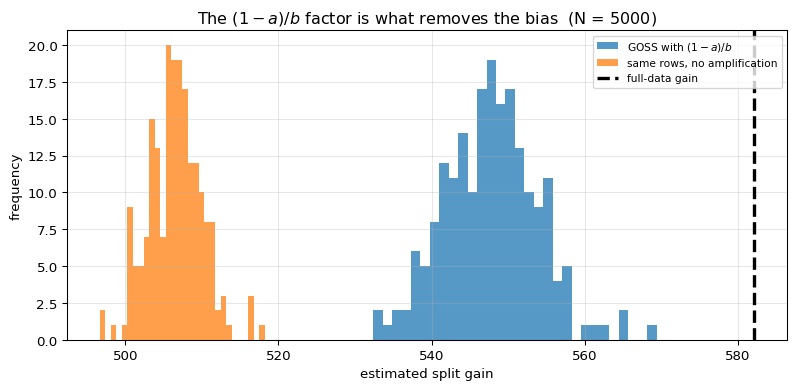


The amplified histogram straddles the true gain; the unamplified one sits
far to the left, because dropping rows removes their gradient mass entirely.
That is the whole reason GOSS is not simply 'drop the easy rows'.


In [15]:
rng_e = np.random.default_rng(11)
N = 5000
Xb = rng_e.normal(size=(N, 1))
yb = np.where(Xb[:, 0] > 0.4, 1.0, 0.0) + rng_e.normal(scale=.3, size=N)
pb = np.full(N, yb.mean())
gb, hb = pb - yb, np.ones(N)
THR = 0.4

def gain_at(mask, gg, hh):
    return 0.5 * (similarity(gg[mask].sum(), hh[mask].sum())
                  + similarity(gg[~mask].sum(), hh[~mask].sum())
                  - similarity(gg.sum(), hh.sum()))

mask_true = Xb[:, 0] <= THR
true_gain = gain_at(mask_true, gb, hb)

amp_est, naive_est = [], []
for rep in range(200):
    srt_b = np.argsort(-np.abs(gb))
    k = int(a_frac * N)
    big_b, rest_b = srt_b[:k], srt_b[k:]
    samp = rng_e.choice(rest_b, size=int(b_frac * len(rest_b)), replace=False)

    w_amp = np.zeros(N); w_amp[big_b] = 1.0; w_amp[samp] = amp
    w_nai = np.zeros(N); w_nai[big_b] = 1.0; w_nai[samp] = 1.0

    amp_est.append(gain_at(mask_true, gb * w_amp, hb * w_amp))
    naive_est.append(gain_at(mask_true, gb * w_nai, hb * w_nai))

amp_est, naive_est = np.array(amp_est), np.array(naive_est)

print(f"N = {N} rows, a = {a_frac}, b = {b_frac}, {len(amp_est)} repetitions\n")
print(f"{'estimator':>28}  {'mean gain':>11}  {'std':>8}  {'bias vs truth':>14}")
print("-" * 68)
print(f"{'full data (truth)':>28}  {true_gain:>11.3f}  {0.0:>8.3f}  {0.0:>14.3f}")
print(f"{'GOSS with (1-a)/b':>28}  {amp_est.mean():>11.3f}  {amp_est.std():>8.3f}  "
      f"{amp_est.mean()-true_gain:>+14.3f}")
print(f"{'same rows, no amplification':>28}  {naive_est.mean():>11.3f}  {naive_est.std():>8.3f}  "
      f"{naive_est.mean()-true_gain:>+14.3f}")
print("-" * 68)

rel_amp = abs(amp_est.mean() - true_gain) / true_gain
rel_nai = abs(naive_est.mean() - true_gain) / true_gain
print(f"\nrelative bias, amplified   : {rel_amp:>7.2%}")
print(f"relative bias, unamplified : {rel_nai:>7.2%}")
print(f"\namplification reduces the bias by "
      f"{100*(1 - rel_amp/rel_nai):.0f}%   (closer to truth: {rel_amp < rel_nai})")

print(f"\nNote that the amplified estimate is NOT exactly unbiased, and it should not")
print(f"be expected to be. The (1-a)/b factor makes the sampled SUMS G and H")
print(f"unbiased, but the gain is a nonlinear function of them - a ratio of squares -")
print(f"so a residual bias survives the correction. What matters in practice is that")
print(f"the same split still wins, and the ranking of candidate splits is preserved.")

plt.figure(figsize=(8.4, 4.2))
plt.hist(amp_est, bins=30, alpha=.75, label=f"GOSS with $(1-a)/b$")
plt.hist(naive_est, bins=30, alpha=.75, label="same rows, no amplification")
plt.axvline(true_gain, color="k", lw=2.5, ls="--", label="full-data gain")
plt.xlabel("estimated split gain"); plt.ylabel("frequency")
plt.title(f"The $(1-a)/b$ factor is what removes the bias  (N = {N})")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("\nThe amplified histogram straddles the true gain; the unamplified one sits")
print("far to the left, because dropping rows removes their gradient mass entirely.")
print("That is the whole reason GOSS is not simply 'drop the easy rows'.")

---
# 5. Checking Against the Real LightGBM

Training `lightgbm` with `num_leaves = 3` and matching regularisation should reproduce
the same split and the same leaf outputs.

Two conventions to know when reading its dump:

* `leaf_value` is the **absolute prediction**, i.e. $\text{init} + \eta\,w^{*}$, not the increment.
* `split_gain` omits the $\tfrac12$, exactly like XGBoost's dump.

In [16]:
params = dict(objective="regression", learning_rate=ETA, num_leaves=NUM_LEAVES,
              min_data_in_leaf=1, min_sum_hessian_in_leaf=0.0, lambda_l2=LAMBDA,
              lambda_l1=0.0, min_gain_to_split=0.0, max_bin=255, feature_fraction=1.0,
              bagging_fraction=1.0, verbose=-1, boost_from_average=True,
              deterministic=True, num_threads=1, seed=0)
ds = lgb.Dataset(X, label=y, feature_name=feature_names, free_raw_data=False)
bst = lgb.train(params, ds, num_boost_round=1)
tree = bst.dump_model()["tree_info"][0]["tree_structure"]

print("lightgbm's tree 0:\n")
print(json.dumps(tree, indent=1)[:900])

lw3, _ = grow_leafwise(NUM_LEAVES, g, h, verbose=False)
print(f"\n\nour leaf-wise tree with num_leaves = {NUM_LEAVES}:\n")
print(f"{'leaf':>5}  {'rows':>5}  {'G':>10}  {'H':>5}  {'w*':>10}  "
      f"{'init + eta*w*':>14}")
print("-" * 58)
ours = []
for k, lf in enumerate(sorted(lw3, key=lambda L: -len(L["idx"]))):
    Gl, Hl = g[lf["idx"]].sum(), h[lf["idx"]].sum()
    w = -Gl / (Hl + LAMBDA)
    val = init_score + ETA * w
    ours.append(round(val, 6))
    print(f"{k:>5}  {len(lf['idx']):>5}  {Gl:>10.4f}  {Hl:>5.0f}  {w:>10.5f}  {val:>14.6f}")
print("-" * 58)

def collect(node, out):
    if "leaf_value" in node:
        out.append((node["leaf_value"], node["leaf_count"]))
    else:
        collect(node["left_child"], out); collect(node["right_child"], out)
    return out

lgb_leaves = collect(tree, [])
lgb_vals = sorted([round(v, 6) for v, c in lgb_leaves])
our_vals = sorted(ours)

print(f"\nroot split : lightgbm = {feature_names[tree['split_feature']]} "
      f"<= {tree['threshold']:.4f},  gain {tree['split_gain']:.4f}")
root_gain, rf, rt = best_split_exact(np.arange(n_samples), g, h)
print(f"             ours     = {feature_names[rf]} <= {rt:.4f},  "
      f"gain {2*root_gain:.4f} (x2 convention)")
print(f"             MATCH: {rf == tree['split_feature'] and np.isclose(rt, tree['threshold'])}"
      f" / gain {np.isclose(2*root_gain, tree['split_gain'], rtol=1e-4)}")

print(f"\nleaf values ours     : {our_vals}")
print(f"leaf values lightgbm : {lgb_vals}")
print(f"MATCH: {np.allclose(our_vals, lgb_vals, atol=1e-6)}")

lgb_pred = bst.predict(X)
our_pred = np.zeros(n_samples)
for lf in lw3:
    Gl, Hl = g[lf["idx"]].sum(), h[lf["idx"]].sum()
    our_pred[lf["idx"]] = init_score + ETA * (-Gl / (Hl + LAMBDA))
print(f"\npredictions MATCH lightgbm: {np.allclose(our_pred, lgb_pred, atol=1e-6)}")
print(f"   ours     : {np.round(our_pred, 5)}")
print(f"   lightgbm : {np.round(lgb_pred, 5)}")

lightgbm's tree 0:

{
 "split_index": 0,
 "split_feature": 1,
 "split_gain": 74.52069854736328,
 "threshold": 3.5500000000000003,
 "decision_type": "<=",
 "default_left": true,
 "missing_type": "None",
 "internal_value": 3.725,
 "internal_weight": 12,
 "internal_count": 12,
 "left_child": {
  "leaf_index": 0,
  "leaf_value": 3.0328571761115675,
  "leaf_weight": 6,
  "leaf_count": 6
 },
 "right_child": {
  "split_index": 1,
  "split_feature": 0,
  "split_gain": 6.658480167388916,
  "threshold": 39.00000000000001,
  "decision_type": "<=",
  "default_left": true,
  "missing_type": "None",
  "internal_value": 4.41714,
  "internal_weight": 6,
  "internal_count": 6,
  "left_child": {
   "leaf_index": 1,
   "leaf_value": 3.8700000448773304,
   "leaf_weight": 1.9999999999999998,
   "leaf_count": 2
  },
  "right_child": {
   "leaf_index": 2,
   "leaf_value": 4.607000045950214,
   "leaf_weight": 4,
   "leaf_count": 4


our leaf-wise tree with num_leaves = 3:

 leaf   rows           G      H     

---
# 6. Summary

| Idea | What it changes | Cost of the approximation |
|---|---|---|
| Histogram binning | thresholds $n-1 \to \#\text{bins}$ | splits limited to bin edges |
| Histogram subtraction | sibling is free | none &mdash; exact |
| Leaf-wise growth | split the best leaf, not the next level | deeper, easier to overfit |
| GOSS | uses a fraction of rows | small variance, corrected by $\frac{1-a}{b}$ |
| EFB | bundles mutually-exclusive sparse columns | negligible on dense data |

**The one idea:** the mathematics of gradient boosting was already settled by XGBoost.
LightGBM's contribution is that the *search* &mdash; not the objective &mdash; is where the time
goes, so it approximates the search and leaves the objective alone.

**The practical consequence:** because growth is leaf-wise, `num_leaves` is the real
capacity knob. Setting `max_depth` alone does not constrain a LightGBM model the way it
constrains an XGBoost one, and a large `num_leaves` on a small dataset overfits quickly.

**What is deliberately left out:** Exclusive Feature Bundling in detail, native
categorical handling, DART, and the distributed histogram-merging protocol.